# Analysis

From `../data/model_results.csv` (made by `run_model.ipynb` on Colab) and the ModelFest
thresholds in `../data/modelfest_baseline.csv`. Runs on a laptop.

In [1]:
import numpy  as np
import pandas as pd
from IPython.display import Image

import figures

results = pd.read_csv("../data/model_results.csv")
# a tie means the model saw no difference: half right (the first 500 trials were saved before this rule)
results["correct"] = np.where(results.score_left > results.score_right, 1.0,
                              np.where(results.score_left == results.score_right, 0.5, 0.0))
print(len(results), "trials")

11000 trials


## Proportion correct

In [2]:
table, count = figures.model_table(results)
print("rows: cycles/deg; columns: contrast; trials per cell:", int(count.min().min()), "to", int(count.max().max()))
print(table.round(2).to_string())

rows: cycles/deg; columns: contrast; trials per cell: 100 to 100
contrast   0.00032  0.00056  0.00100  0.00178  0.00316  0.00562  0.01000  0.01778  0.03162  0.05623  0.10000
frequency                                                                                                   
1.12          0.00     0.00     0.04     0.00     0.19     0.58      1.0      1.0      1.0      1.0      1.0
2.00          0.44     0.45     0.27     0.05     0.54     1.00      1.0      1.0      1.0      1.0      1.0
2.83          0.39     0.45     0.49     0.41     0.99     1.00      1.0      1.0      1.0      1.0      1.0
4.00          0.45     0.41     0.24     0.20     0.96     1.00      1.0      1.0      1.0      1.0      1.0
5.66          0.18     0.20     0.24     0.39     1.00     1.00      1.0      1.0      1.0      1.0      1.0
8.00          0.53     0.45     0.33     0.10     0.38     1.00      1.0      1.0      1.0      1.0      1.0
11.30         0.44     0.47     0.22     0.39     0.55     1.00

## How far the model leans each way

The score is how much more the model wants to say "left" than "right". The difference between the
two displays of a trial (Gabor left minus Gabor right) is above 0 when the model gets it right.

In [3]:
results["difference"] = results.score_left - results.score_right
print(results.pivot_table(index="frequency", columns="contrast", values="difference").round(3).to_string())

contrast   0.00032  0.00056  0.00100  0.00178  0.00316  0.00562  0.01000  0.01778  0.03162  0.05623  0.10000
frequency                                                                                                   
1.12        -0.001   -0.002   -0.004   -0.015   -0.028    0.003    0.305    0.517    0.856    1.237    1.343
2.00        -0.003   -0.004   -0.009   -0.033    0.015    0.163    0.470    0.817    1.323    1.896    2.041
2.83        -0.004   -0.006   -0.011   -0.021    0.052    0.506    1.323    2.074    2.808    3.009    3.029
4.00        -0.003   -0.005   -0.017   -0.042    0.151    1.453    2.678    3.489    4.616    4.218    4.137
5.66        -0.005   -0.011   -0.025   -0.036    0.382    1.719    3.425    4.570    5.670    5.210    5.902
8.00        -0.000   -0.002   -0.006   -0.029   -0.030    0.355    1.876    4.279    5.178    5.166    6.115
11.30       -0.005   -0.006   -0.034   -0.020   -0.001    0.824    1.826    2.064    2.420    3.249    5.089
16.00       -0.001 

## Psychometric functions and thresholds

The threshold at each frequency: the faintest contrast at which the model is right in at least
75% of the trials. The true threshold lies between that contrast and the one below it. No curve
is fitted: the model's data jump from guessing to 100% within one step of contrast.

 frequency  threshold (%)  contrast below (%)
      1.12          1.000               0.562
      2.00          0.562               0.316
      2.83          0.316               0.178
      4.00          0.316               0.178
      5.66          0.316               0.178
      8.00          0.562               0.316
     11.30          0.562               0.316
     16.00          0.562               0.316
     22.60          0.562               0.316
     30.00          1.000               0.562


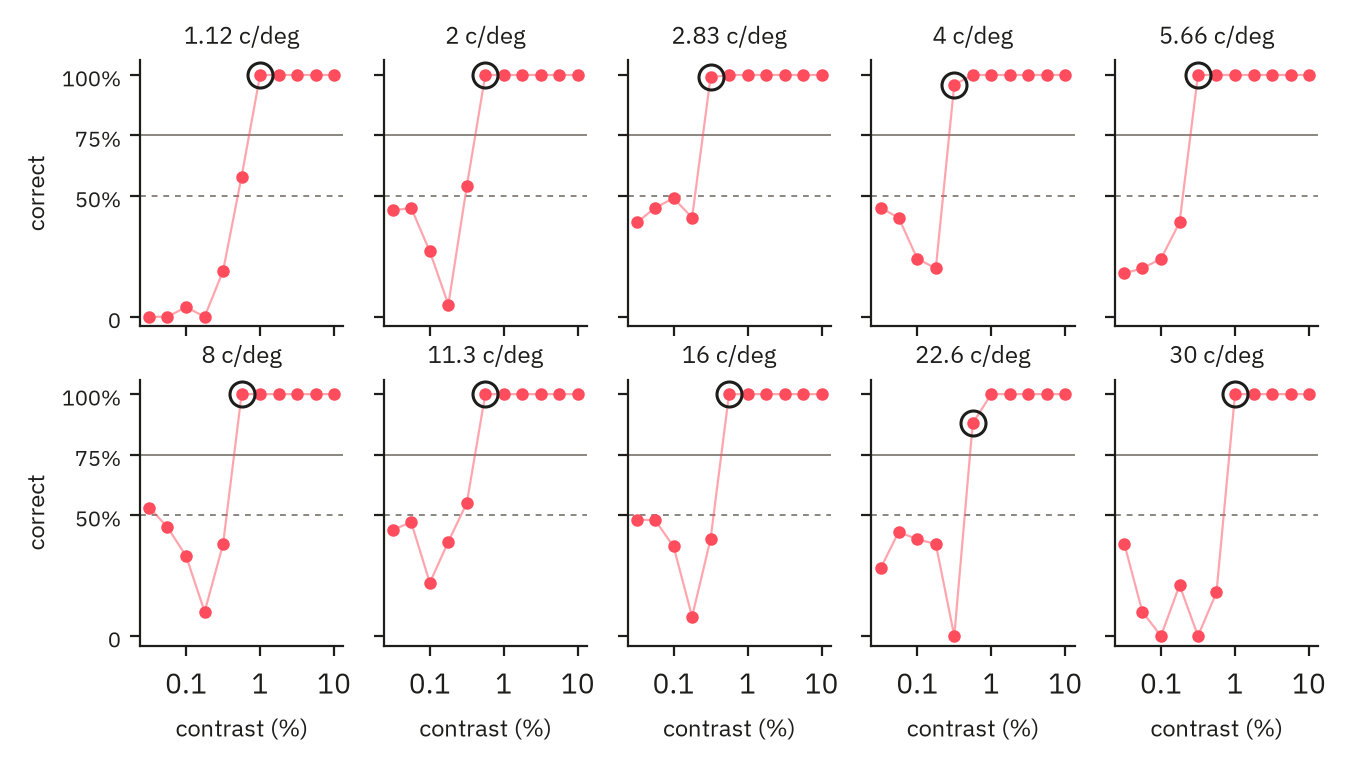

In [4]:
figures.psychometric_figure("../img/vlm_psychometric.png", results)
thresholds = figures.model_thresholds(results)
print((thresholds.assign(threshold=lambda t: 100 * t.threshold, below=lambda t: 100 * t.below)
       .rename(columns={"threshold": "threshold (%)", "below": "contrast below (%)"}).round(3).to_string(index=False)))
Image("../img/vlm_psychometric.png")

## Model versus humans

 frequency  human_sensitivity  model_sensitivity  up_to
      1.12               66.0              100.0  178.0
      2.00               91.0              178.0  316.0
      2.83              116.0              316.0  562.0
      4.00              128.0              316.0  562.0
      5.66               98.0              316.0  562.0
      8.00               70.0              178.0  316.0
     11.30               42.0              178.0  316.0
     16.00               20.0              178.0  316.0
     22.60                9.0              178.0  316.0
     30.00                4.0              100.0  178.0


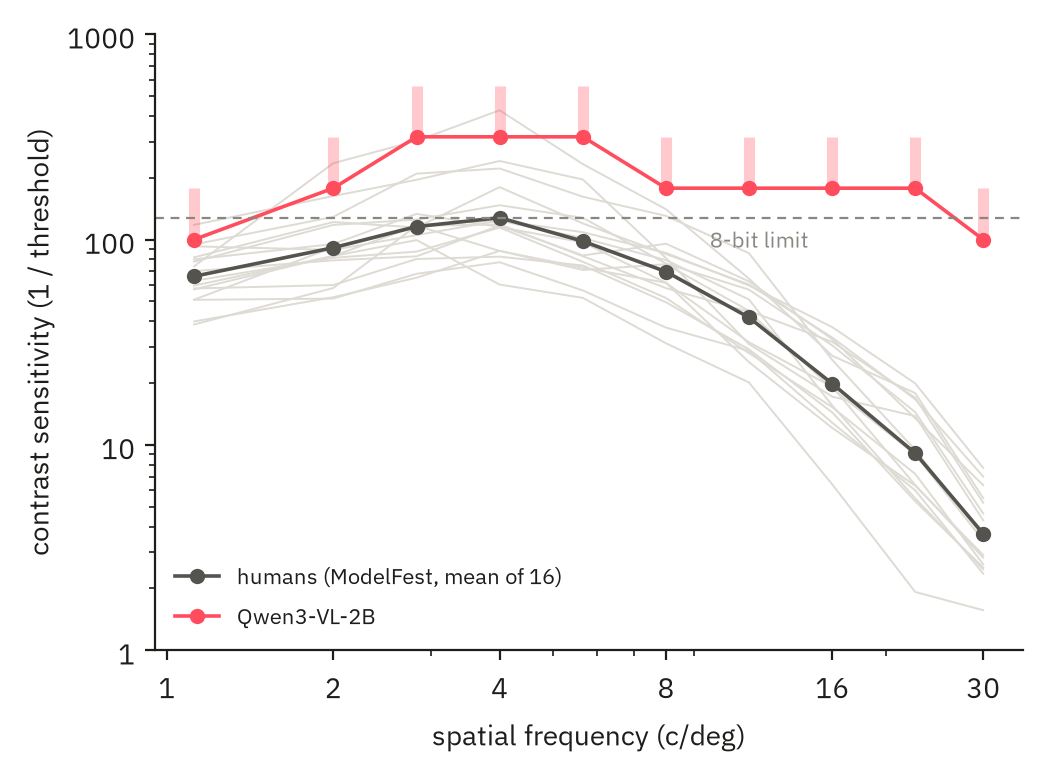

In [5]:
figures.csf_compare_figure("../img/vlm_vs_modelfest.png", thresholds)
f, logs, mean, se = figures.modelfest_csf()
human = pd.DataFrame({"frequency": f, "human_sensitivity": np.round(10 ** mean)})
model = thresholds.assign(model_sensitivity=lambda t: np.round(1 / t.threshold),
                          up_to=lambda t: np.round(1 / t.below))[["frequency", "model_sensitivity", "up_to"]]
print(human.merge(model, on="frequency", how="left").to_string(index=False))
Image("../img/vlm_vs_modelfest.png")

## The "left" habit (Figure 9)

How often the model would say "left" with no image, a grey image, the two words swapped in the
question (values printed by `run_layers.ipynb`), and in the main run for Gabors of 0.1% or fainter.

displays at 0.1% or fainter: 6000
first word 'left', Gabor on the left:  1.0
first word 'left', Gabor on the right: 1.0


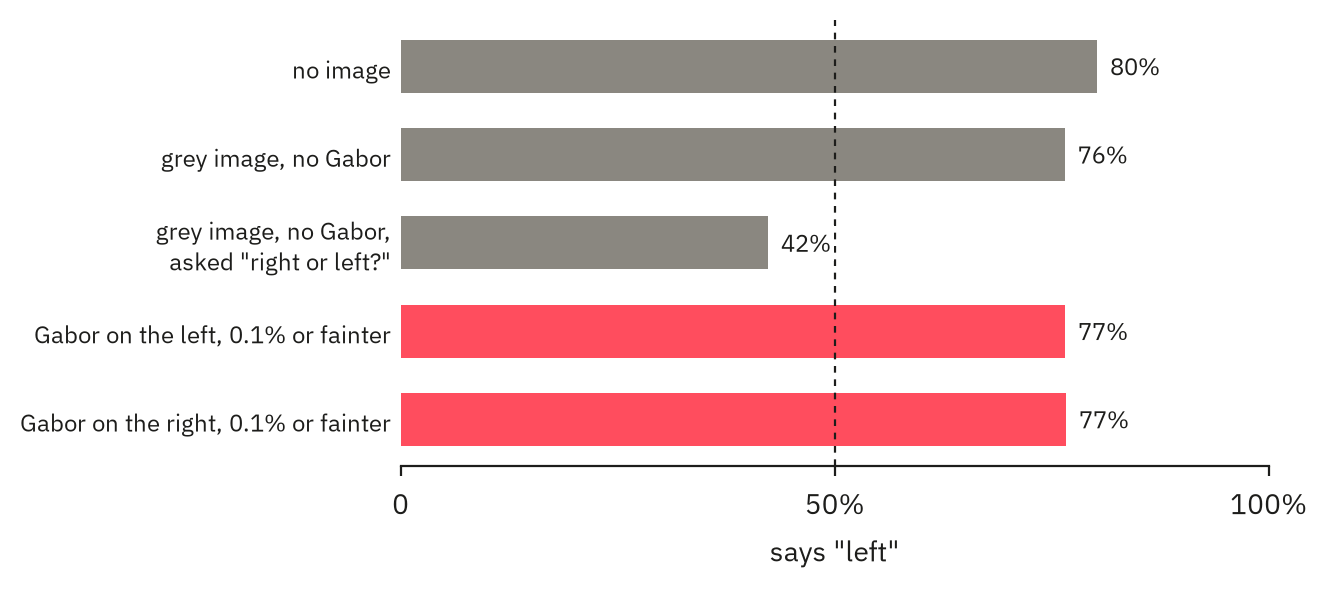

In [6]:
figures.left_habit_figure("../img/vlm_left_habit.png", results)
faint = results[results.contrast <= 0.001 + 1e-9]
print("displays at 0.1% or fainter:", 2 * len(faint))
print("first word 'left', Gabor on the left: ", (faint.score_left > 0).mean())
print("first word 'left', Gabor on the right:", (faint.score_right > 0).mean())
Image("../img/vlm_left_habit.png", width=560)

## Read-out at every layer (Figure 6f)

From `../data/layer_readout.csv`, made by `run_layers.ipynb` on Colab: proportion correct of a
logistic-regression read-out at each layer, and of the model's own answer, on the same 100 pairs.

                    read-out, worst layer  answer
frequency contrast                               
4         0.000001                   0.98    0.46
          0.000003                   0.94    0.43
          0.000010                   0.95    0.63
          0.000032                   1.00    0.42
          0.000100                   1.00    0.43
          0.000316                   1.00    0.41
          0.001000                   1.00    0.29
          0.003162                   1.00    0.96
          0.010000                   1.00    1.00
          0.031623                   1.00    1.00
          0.100000                   1.00    1.00
16        0.000001                   0.94    0.52
          0.000003                   0.97    0.47
          0.000010                   1.00    0.49
          0.000032                   1.00    0.56
          0.000100                   1.00    0.45
          0.000316                   1.00    0.46
          0.001000                   1.00    0.35


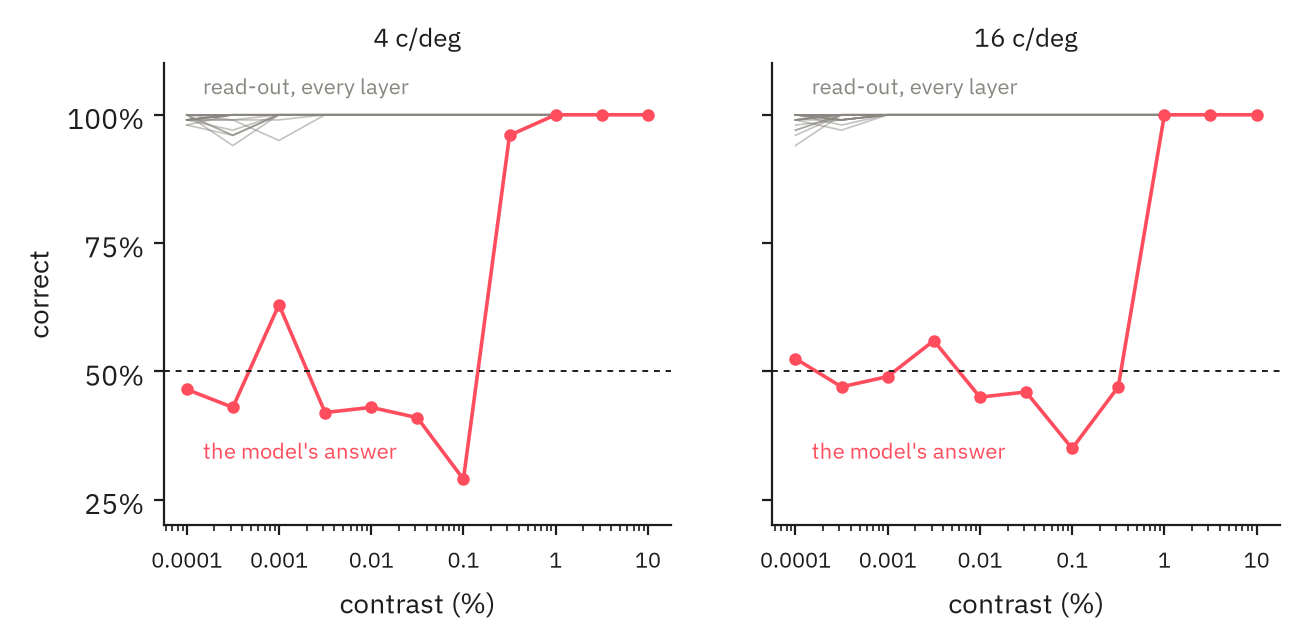

In [7]:
readout = pd.read_csv("../data/layer_readout.csv")
table = readout.pivot_table(index=["frequency", "contrast"], columns="layer", values="correct")
layers = table.drop(columns=["answer", "language 0"])
print(pd.DataFrame({"read-out, worst layer": layers.min(axis=1), "answer": table["answer"]}).round(2))
figures.readout_figure("../img/vlm_readout.png", readout)
Image("../img/vlm_readout.png", width=720)